# Program 1 – Implement and Compare Gradient-Based Optimizers

**Objective:** Train the *same* deep MLP with four optimizers (SGD, AdaGrad, RMSProp, Adam) and compare how fast they converge.

**Dataset:** MNIST (70,000 grayscale 28×28 handwritten digits, 10 classes)

**Key tasks**
1. Build the same MLP for every optimizer.
2. Track loss and accuracy curves.
3. Plot an optimizer performance comparison.

## Theory (for viva)

All optimizers update weights $w$ using the gradient $g_t = \nabla_w L$ of the loss.

| Optimizer | Update rule (simplified) | Idea |
|---|---|---|
| **SGD** | $w \leftarrow w - \eta\, g_t$ | Step against gradient with fixed learning rate $\eta$. Simple but slow, can oscillate. |
| **AdaGrad** | $G_t = G_{t-1} + g_t^2,\quad w \leftarrow w - \frac{\eta}{\sqrt{G_t}+\epsilon} g_t$ | Per-parameter learning rate; rarely-updated weights get bigger steps. $G_t$ only grows, so learning rate keeps shrinking → may stop learning early. |
| **RMSProp** | $E[g^2]_t = \rho E[g^2]_{t-1} + (1-\rho) g_t^2,\quad w \leftarrow w - \frac{\eta}{\sqrt{E[g^2]_t}+\epsilon} g_t$ | Fixes AdaGrad by using a *moving average* of squared gradients instead of a sum. |
| **Adam** | $m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t$, $v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2$, bias-correct $\hat m, \hat v$, $w \leftarrow w - \eta \frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$ | Momentum (1st moment) + RMSProp (2nd moment). Usually fastest convergence. |

**Fair comparison rule:** same architecture, same initial weights (same random seed), same data, same epochs, same batch size — only the optimizer changes.

## Step 1 – Import libraries

In [1]:
import keras  # Keras 3 API (runs on TensorFlow backend)
from keras import layers  # Layer classes (Dense, Dropout, Embedding, ...)
import matplotlib.pyplot as plt  # Plotting graphs
import numpy as np  # Numerical arrays
import tensorflow as tf  # TensorFlow (tensors, GradientTape, seeds)

print("TensorFlow version:", tf.__version__)   # Show installed TF version

TensorFlow version: 2.21.0


## Step 2 – Load and preprocess MNIST

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()  # Download/load MNIST train & test splits

print("Train images:", x_train.shape, "Train labels:", y_train.shape)  # (60000, 28, 28) and (60000,)
print("Test images :", x_test.shape, "Test labels :", y_test.shape)    # (10000, 28, 28) and (10000,)

x_train = x_train.reshape(-1, 28 * 28).astype("float32") / 255.0  # Flatten 28x28 -> 784 and scale pixels 0-255 to 0-1
x_test = x_test.reshape(-1, 28 * 28).astype("float32") / 255.0    # Same preprocessing for test set

print("After flatten:", x_train.shape)  # Now (60000, 784) – one row per image

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Train images: (60000, 28, 28) Train labels: (60000,)
Test images : (10000, 28, 28) Test labels : (10000,)
After flatten: (60000, 784)


## Step 3 – Define ONE MLP architecture (reused for every optimizer)

In [3]:
def build_mlp():                                        # Function returns a fresh, untrained model each call
    model = keras.Sequential([                          # Sequential = layers stacked one after another
        keras.Input(shape=(784,)),                      # Input layer: 784 pixel values per image
        layers.Dense(256, activation="relu"),           # Hidden layer 1: 256 neurons, ReLU activation
        layers.Dense(128, activation="relu"),           # Hidden layer 2: 128 neurons, ReLU activation
        layers.Dense(64, activation="relu"),            # Hidden layer 3: 64 neurons, ReLU activation
        layers.Dense(10, activation="softmax"),         # Output layer: 10 classes, softmax gives probabilities
    ])
    return model                                        # Give back the built model

build_mlp().summary()                                   # Print layer shapes and parameter counts once

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

## Step 4 – Define the four optimizers

In [4]:
# Each entry is a function (lambda) so a NEW optimizer object is made for each model
# (an optimizer keeps internal state, so it must not be shared between models)
optimizers = {
    "SGD": lambda: keras.optimizers.SGD(learning_rate=0.01),          # Plain gradient descent, lr = 0.01
    "AdaGrad": lambda: keras.optimizers.Adagrad(learning_rate=0.01),  # Adaptive lr from sum of squared grads
    "RMSProp": lambda: keras.optimizers.RMSprop(learning_rate=0.001), # Adaptive lr from moving avg of squared grads
    "Adam": lambda: keras.optimizers.Adam(learning_rate=0.001),       # Momentum + RMSProp, default lr 0.001
}

EPOCHS = 10          # Number of full passes over the training data
BATCH_SIZE = 128     # Number of samples per gradient update

## Step 5 – Train the same model with each optimizer and record history

In [5]:
histories = {}       # Will store training history (loss/accuracy per epoch) for each optimizer
test_results = {}    # Will store final test accuracy for each optimizer

for name, make_optimizer in optimizers.items():          # Loop over optimizer name and its constructor
    print(f"\n===== Training with {name} =====")         # Show which optimizer is running
    tf.random.set_seed(42)                               # Same seed -> identical initial weights for fair comparison
    model = build_mlp()                                  # Fresh model with same architecture
    model.compile(                                       # Configure the model for training
        optimizer=make_optimizer(),                      # Create a new optimizer instance
        loss="sparse_categorical_crossentropy",          # Cross-entropy for integer labels (0-9)
        metrics=["accuracy"],                            # Also track classification accuracy
    )
    history = model.fit(                                 # Train the model
        x_train, y_train,                                # Training inputs and labels
        epochs=EPOCHS,                                   # How many epochs
        batch_size=BATCH_SIZE,                           # Mini-batch size
        validation_split=0.1,                            # Hold out last 10% of train data for validation
        verbose=2,                                       # Print one line per epoch
    )
    histories[name] = history.history                    # Save dict: loss, accuracy, val_loss, val_accuracy
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)  # Evaluate on unseen test data
    test_results[name] = test_acc                        # Store test accuracy
    print(f"{name}: test loss = {test_loss:.4f}, test accuracy = {test_acc:.4f}")  # Report result


===== Training with SGD =====
Epoch 1/10
422/422 - 1s - 2ms/step - accuracy: 0.6022 - loss: 1.4357 - val_accuracy: 0.8640 - val_loss: 0.6009
Epoch 2/10
422/422 - 0s - 1ms/step - accuracy: 0.8638 - loss: 0.5133 - val_accuracy: 0.9122 - val_loss: 0.3462
Epoch 3/10
422/422 - 0s - 1ms/step - accuracy: 0.8941 - loss: 0.3776 - val_accuracy: 0.9228 - val_loss: 0.2823
Epoch 4/10
422/422 - 0s - 1ms/step - accuracy: 0.9069 - loss: 0.3260 - val_accuracy: 0.9330 - val_loss: 0.2502
Epoch 5/10
422/422 - 1s - 1ms/step - accuracy: 0.9158 - loss: 0.2942 - val_accuracy: 0.9387 - val_loss: 0.2281
Epoch 6/10
422/422 - 1s - 2ms/step - accuracy: 0.9228 - loss: 0.2705 - val_accuracy: 0.9433 - val_loss: 0.2112
Epoch 7/10
422/422 - 1s - 2ms/step - accuracy: 0.9282 - loss: 0.2512 - val_accuracy: 0.9463 - val_loss: 0.1972
Epoch 8/10
422/422 - 1s - 2ms/step - accuracy: 0.9323 - loss: 0.2350 - val_accuracy: 0.9505 - val_loss: 0.1853
Epoch 9/10
422/422 - 1s - 2ms/step - accuracy: 0.9369 - loss: 0.2209 - val_accura

## Step 6 – Plot loss and accuracy curves for all optimizers

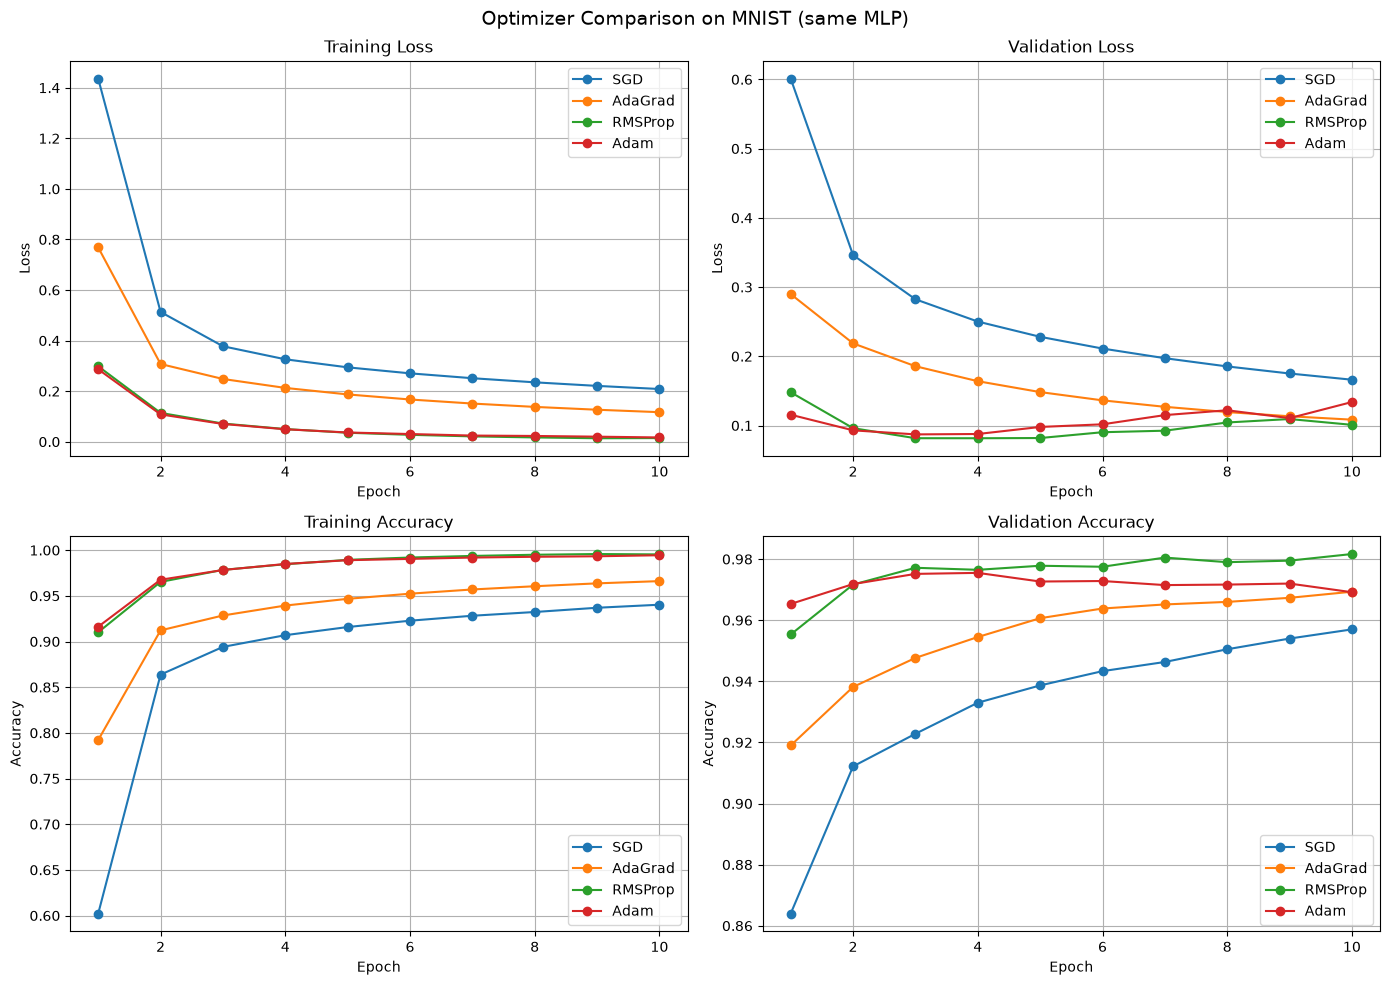

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))          # 2x2 grid of plots
epochs_range = np.arange(1, EPOCHS + 1)                    # X-axis values: 1..EPOCHS

for name, hist in histories.items():                       # Draw one line per optimizer on every subplot
    axes[0, 0].plot(epochs_range, hist["loss"], marker="o", label=name)          # Training loss
    axes[0, 1].plot(epochs_range, hist["val_loss"], marker="o", label=name)      # Validation loss
    axes[1, 0].plot(epochs_range, hist["accuracy"], marker="o", label=name)      # Training accuracy
    axes[1, 1].plot(epochs_range, hist["val_accuracy"], marker="o", label=name)  # Validation accuracy

titles = ["Training Loss", "Validation Loss", "Training Accuracy", "Validation Accuracy"]  # Subplot titles
for ax, title in zip(axes.flat, titles):                   # Loop over the 4 subplots with their titles
    ax.set_title(title)                                    # Set subplot title
    ax.set_xlabel("Epoch")                                 # X-axis label
    ax.set_ylabel("Loss" if "Loss" in title else "Accuracy")  # Y-axis label depends on plot type
    ax.legend()                                            # Show which colour is which optimizer
    ax.grid(True)                                          # Light grid for readability

plt.suptitle("Optimizer Comparison on MNIST (same MLP)", fontsize=14)  # Overall figure title
plt.tight_layout()                                         # Avoid overlapping labels
plt.show()                                                 # Display the figure

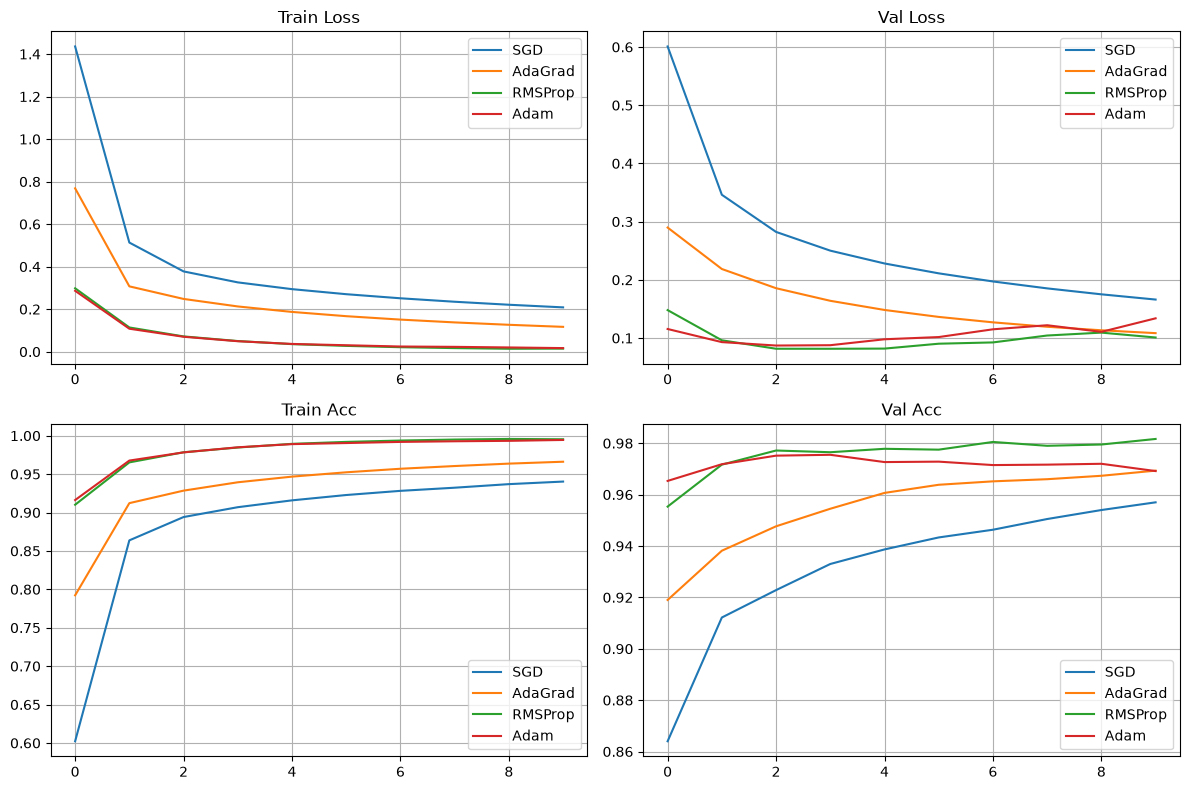

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for n, h in histories.items():
    for a, k in zip(ax.flat, ["loss", "val_loss", "accuracy", "val_accuracy"]):
        a.plot(h[k], label=n)
for a, t in zip(ax.flat, ["Train Loss", "Val Loss", "Train Acc", "Val Acc"]):
    a.set(title=t)
    a.legend()
    a.grid()
plt.tight_layout()
plt.show()

## Step 7 – Bar chart of final test accuracy

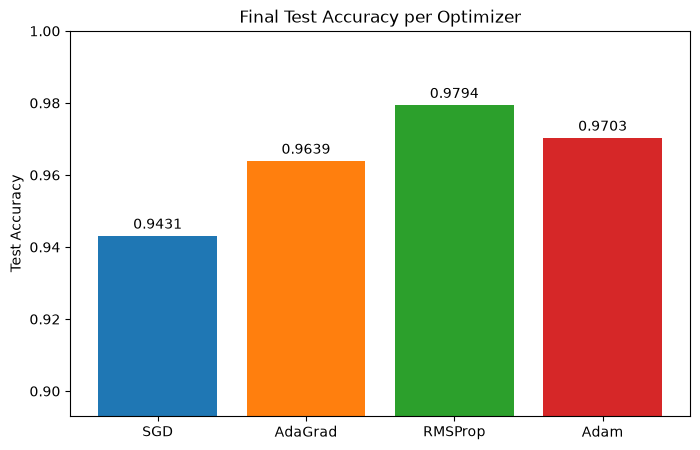

In [9]:
names = list(test_results.keys())                          # Optimizer names
accs = [test_results[n] for n in names]                    # Their test accuracies

plt.figure(figsize=(8, 5))                                 # New figure
bars = plt.bar(names, accs, color=["tab:blue", "tab:orange", "tab:green", "tab:red"])  # One bar per optimizer
for bar, acc in zip(bars, accs):                           # Write value on top of each bar
    plt.text(bar.get_x() + bar.get_width() / 2, acc + 0.002, f"{acc:.4f}", ha="center")  # Centered text label
plt.ylim(min(accs) - 0.05, 1.0)                            # Zoom y-axis so differences are visible
plt.ylabel("Test Accuracy")                                # Y-axis label
plt.title("Final Test Accuracy per Optimizer")             # Plot title
plt.show()                                                 # Display plot

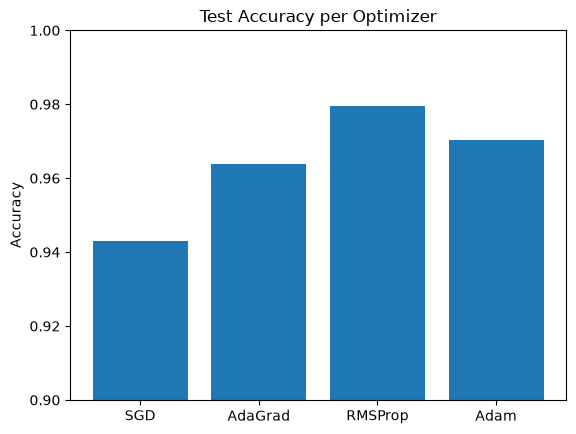

In [15]:
plt.bar(test_results.keys(), test_results.values())
plt.title("Test Accuracy per Optimizer")
plt.ylabel("Accuracy")
plt.ylim(0.9, 1)
plt.show()

## Step 8 – Summary table

In [16]:
print(f"{'Optimizer':<10} | {'Final Train Loss':>16} | {'Final Val Acc':>13} | {'Test Acc':>8}")  # Table header
print("-" * 58)                                            # Separator line
for name in names:                                         # One row per optimizer
    h = histories[name]                                    # History dict for this optimizer
    print(f"{name:<10} | {h['loss'][-1]:>16.4f} | {h['val_accuracy'][-1]:>13.4f} | {test_results[name]:>8.4f}")  # Last-epoch values

Optimizer  | Final Train Loss | Final Val Acc | Test Acc
----------------------------------------------------------
SGD        |           0.2085 |        0.9570 |   0.9431
AdaGrad    |           0.1169 |        0.9693 |   0.9639
RMSProp    |           0.0145 |        0.9817 |   0.9794
Adam       |           0.0169 |        0.9692 |   0.9703


## Expected observations
- **Adam** and **RMSProp** converge fastest (loss drops sharply in first 1–2 epochs).
- **SGD** (no momentum) converges slowest — steady but small steps.
- **AdaGrad** starts well but slows down because its accumulated squared gradients keep shrinking the learning rate.

## Viva questions
1. Why do we fix the random seed before building each model? → So all optimizers start from identical weights (fair comparison).
2. What is the main drawback of AdaGrad? → Learning rate decays monotonically and can become too small.
3. How does RMSProp fix it? → Uses exponential moving average of squared gradients instead of their sum.
4. What does Adam add over RMSProp? → Momentum (first moment) plus bias correction.
5. What is the role of `validation_split`? → Keeps part of the training data unseen during training to monitor generalization.